In [1]:
import nltk
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

Q1.  Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports,
technology, food, books, etc.).
1. Convert text to lowercase and remove punctua on using re.
2. Tokenize the text into words and sentences.
3. Split using split() and word_tokenize() and compare how Python split and NLTK’s
word_tokenize() differ.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribu on (excluding stopwords).

In [8]:
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

paragraph = "Artificial Intelligence is transforming how humanity interacts with technology daily. This rapid evolution brings both incredible innovations and complex ethical considerations. Many industries now rely on automated machine learning systems to process vast amounts of complex data. However, understanding the underlying neural mechanics of modern AI remains a profound scientific challenge. Researchers worldwide are collaborating to establish open standards for safe, aligned model deployment. Ultimately, balancing power with responsibility is key to securing a beneficial future."

print("Original Paragraph:")
print(paragraph)

cleaned_lower = paragraph.lower()
cleaned_no_punc = re.sub(r'[^\w\s]', '', cleaned_lower)
print("\n1. Cleaned and Lowercased Text:")
print(cleaned_no_punc)

words_nltk = word_tokenize(paragraph)
sentences_nltk = sent_tokenize(paragraph)
print("\n2. Tokenized Sentences:")
display(sentences_nltk)

words_split = paragraph.split()
print("\n3. Comparing split() vs word_tokenize():")
print(f"Number of tokens via split(): {len(words_split)}")
print(f"Number of tokens via word_tokenize(): {len(words_nltk)}")
print("\nFirst 10 split() tokens:\n", words_split[:10])
print("First 10 word_tokenize() tokens:\n", words_nltk[:10])
print("\nDifference: NLTK's word_tokenize splits punctuation marks as separate tokens (e.g., periods, commas), whereas split() treats punctuation attached to adjacent words as part of the token.")

stop_words = set(stopwords.words('english'))
cleaned_tokens = word_tokenize(cleaned_no_punc)
filtered_words = [word for word in cleaned_tokens if word not in stop_words]
print("\n4. Tokens after Stopword Removal:")
print(filtered_words)
freq_dist = Counter(filtered_words)
print("\n5. Word Frequency Distribution:")
for word, count in freq_dist.most_common():
    print(f"{word}: {count}")

Original Paragraph:
Artificial Intelligence is transforming how humanity interacts with technology daily. This rapid evolution brings both incredible innovations and complex ethical considerations. Many industries now rely on automated machine learning systems to process vast amounts of complex data. However, understanding the underlying neural mechanics of modern AI remains a profound scientific challenge. Researchers worldwide are collaborating to establish open standards for safe, aligned model deployment. Ultimately, balancing power with responsibility is key to securing a beneficial future.

1. Cleaned and Lowercased Text:
artificial intelligence is transforming how humanity interacts with technology daily this rapid evolution brings both incredible innovations and complex ethical considerations many industries now rely on automated machine learning systems to process vast amounts of complex data however understanding the underlying neural mechanics of modern ai remains a profound

['Artificial Intelligence is transforming how humanity interacts with technology daily.',
 'This rapid evolution brings both incredible innovations and complex ethical considerations.',
 'Many industries now rely on automated machine learning systems to process vast amounts of complex data.',
 'However, understanding the underlying neural mechanics of modern AI remains a profound scientific challenge.',
 'Researchers worldwide are collaborating to establish open standards for safe, aligned model deployment.',
 'Ultimately, balancing power with responsibility is key to securing a beneficial future.']


3. Comparing split() vs word_tokenize():
Number of tokens via split(): 76
Number of tokens via word_tokenize(): 85

First 10 split() tokens:
 ['Artificial', 'Intelligence', 'is', 'transforming', 'how', 'humanity', 'interacts', 'with', 'technology', 'daily.']
First 10 word_tokenize() tokens:
 ['Artificial', 'Intelligence', 'is', 'transforming', 'how', 'humanity', 'interacts', 'with', 'technology', 'daily']

Difference: NLTK's word_tokenize splits punctuation marks as separate tokens (e.g., periods, commas), whereas split() treats punctuation attached to adjacent words as part of the token.

4. Tokens after Stopword Removal:
['artificial', 'intelligence', 'transforming', 'humanity', 'interacts', 'technology', 'daily', 'rapid', 'evolution', 'brings', 'incredible', 'innovations', 'complex', 'ethical', 'considerations', 'many', 'industries', 'rely', 'automated', 'machine', 'learning', 'systems', 'process', 'vast', 'amounts', 'complex', 'data', 'however', 'understanding', 'underlying', 'neu

1. Extract all words with only alphabets using re.findall()
2. Remove stop words using NLTK’s stopword list
3. Perform stemming with PorterStemmer
4. Perform lemma za on with WordNetLemma zer
5. Compare the stemmed and lemma zed outputs and explain when you’d prefer one over
the other.

In [9]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())
print("1. Alphabetic words:")
print(alpha_words[:15], "...")

stop_words = set(stopwords.words('english'))
alpha_filtered = [word for word in alpha_words if word not in stop_words]
print("\n2. Filtered Alphabetic words:")
print(alpha_filtered)

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in alpha_filtered]
print("\n3. Stemmed words:")
print(stemmed_words)

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in alpha_filtered]
print("\n4. Lemmatized words:")
print(lemmatized_words)

comparison_df = pd.DataFrame({
    'Original': alpha_filtered,
    'Stemmed (Porter)': stemmed_words,
    'Lemmatized (WordNet)': lemmatized_words
})
print("\n5. Comparison Table:")
display(comparison_df.head(15))

print("""
Comparison & Explanation:
- Stemming (PorterStemmer) uses heuristic rules to chop off word endings (suffixes) to find the word stem. This can lead to non-dictionary words (e.g., 'humanity' -> 'human', 'technology' -> 'technolog', 'industries' -> 'industri').
- Lemmatization (WordNetLemmatizer) uses vocabulary and morphological analysis to return the dictionary base form (lemma) of a word, ensuring it is a valid linguistic word (e.g., 'industries' -> 'industry').

When to prefer which:
- Choose Stemming when speed, simplicity, and low computational overhead are critical, such as during quick document indexing in large search engines.
- Choose Lemmatization when context and grammatically correct root words are required, such as in chatbots, sentiment analysis, and machine translation applications.
""")

1. Alphabetic words:
['artificial', 'intelligence', 'is', 'transforming', 'how', 'humanity', 'interacts', 'with', 'technology', 'daily', 'this', 'rapid', 'evolution', 'brings', 'both'] ...

2. Filtered Alphabetic words:
['artificial', 'intelligence', 'transforming', 'humanity', 'interacts', 'technology', 'daily', 'rapid', 'evolution', 'brings', 'incredible', 'innovations', 'complex', 'ethical', 'considerations', 'many', 'industries', 'rely', 'automated', 'machine', 'learning', 'systems', 'process', 'vast', 'amounts', 'complex', 'data', 'however', 'understanding', 'underlying', 'neural', 'mechanics', 'modern', 'ai', 'remains', 'profound', 'scientific', 'challenge', 'researchers', 'worldwide', 'collaborating', 'establish', 'open', 'standards', 'safe', 'aligned', 'model', 'deployment', 'ultimately', 'balancing', 'power', 'responsibility', 'key', 'securing', 'beneficial', 'future']

3. Stemmed words:
['artifici', 'intellig', 'transform', 'human', 'interact', 'technolog', 'daili', 'rapid', 

,Original,Stemmed (Porter),Lemmatized (WordNet)
0,artificial,artifici,artificial
1,intelligence,intellig,intelligence
2,transforming,transform,transforming
3,humanity,human,humanity
4,interacts,interact,interacts
5,technology,technolog,technology
6,daily,daili,daily
7,rapid,rapid,rapid
8,evolution,evolut,evolution
9,brings,bring,brings



Comparison & Explanation:
- Stemming (PorterStemmer) uses heuristic rules to chop off word endings (suffixes) to find the word stem. This can lead to non-dictionary words (e.g., 'humanity' -> 'human', 'technology' -> 'technolog', 'industries' -> 'industri').
- Lemmatization (WordNetLemmatizer) uses vocabulary and morphological analysis to return the dictionary base form (lemma) of a word, ensuring it is a valid linguistic word (e.g., 'industries' -> 'industry').

When to prefer which:
- Choose Stemming when speed, simplicity, and low computational overhead are critical, such as during quick document indexing in large search engines.
- Choose Lemmatization when context and grammatically correct root words are required, such as in chatbots, sentiment analysis, and machine translation applications.



Q3. Choose 3 short texts of your own (e.g., different news headlines, product reviews).
1. Use CountVectorizer to generate the Bag of Words representa on.
2. Use TfidfVectorizer to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.

In [10]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Stock market indexes soared today as technology shares rallied on positive economic reports.",
    "The new smartphone features an outstanding camera layout and incredibly long battery life.",
    "A classic recipe for homemade Italian pasta requires fresh eggs, high quality flour, and patience."
]

bow_vectorizer = CountVectorizer(stop_words='english')
bow_matrix = bow_vectorizer.fit_transform(texts)
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())
print("1. Bag of Words Representation:")
display(bow_df)

tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out())
print("\n2. TF-IDF Representation:")
display(tfidf_df)

feature_names = tfidf_vectorizer.get_feature_names_out()
print("\n3. Top 3 Keywords per Text via TF-IDF:")
for idx, row in enumerate(tfidf_matrix.toarray()):
    top_indices = np.argsort(row)[::-1][:3]
    top_keywords = [(feature_names[i], round(row[i], 3)) for i in top_indices]
    print(f"\nText {idx+1}: \"{texts[idx]}\"")
    print(f"Top 3 keywords: {top_keywords}")

1. Bag of Words Representation:


,battery,camera,classic,economic,eggs,features,flour,fresh,high,homemade,...,rallied,recipe,reports,requires,shares,smartphone,soared,stock,technology,today
0,0,0,0,1,0,0,0,0,0,0,...,1,0,1,0,1,0,1,1,1,1
1,1,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,0,0,1,0,1,0,1,1,1,1,...,0,1,0,1,0,0,0,0,0,0



2. TF-IDF Representation:


,battery,camera,classic,economic,eggs,features,flour,fresh,high,homemade,...,rallied,recipe,reports,requires,shares,smartphone,soared,stock,technology,today
0,0.000000,0.000000,0.000000,0.301511,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.301511,0.000000,0.301511,0.000000,0.301511,0.000000,0.301511,0.301511,0.301511,0.301511
1,0.316228,0.316228,0.000000,0.000000,0.000000,0.316228,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.316228,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.288675,0.000000,0.288675,0.000000,0.288675,0.288675,0.288675,0.288675,...,0.000000,0.288675,0.000000,0.288675,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000



3. Top 3 Keywords per Text via TF-IDF:

Text 1: "Stock market indexes soared today as technology shares rallied on positive economic reports."
Top 3 keywords: [('today', np.float64(0.302)), ('technology', np.float64(0.302)), ('stock', np.float64(0.302))]

Text 2: "The new smartphone features an outstanding camera layout and incredibly long battery life."
Top 3 keywords: [('smartphone', np.float64(0.316)), ('camera', np.float64(0.316)), ('new', np.float64(0.316))]

Text 3: "A classic recipe for homemade Italian pasta requires fresh eggs, high quality flour, and patience."
Top 3 keywords: [('recipe', np.float64(0.289)), ('fresh', np.float64(0.289)), ('requires', np.float64(0.289))]


Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs
Blockchain).
1. Preprocess and tokenize both texts.
2. Calculate:
a. Jaccard Similarity using sets
b. Cosine Similarity using TfidfVectorizer + cosine_similarity()
c. Analyze which similarity metric gives be er insights in your case.

In [11]:
from sklearn.metrics.pairwise import cosine_similarity

tech1_ai = "Artificial Intelligence focuses on building machines that can mimic human cognition and reasoning to solve complex problems."
tech2_blockchain = "Blockchain technology builds a decentralized, immutable ledger system to store transactional records securely and transparently."

def preprocess_and_tokenize(text):
    clean = re.sub(r'[^\w\s]', '', text.lower())
    return set(clean.split())

tokens_ai = preprocess_and_tokenize(tech1_ai)
tokens_blockchain = preprocess_and_tokenize(tech2_blockchain)

print("AI Tokens:", tokens_ai)
print("Blockchain Tokens:", tokens_blockchain)

intersection = tokens_ai.intersection(tokens_blockchain)
union = tokens_ai.union(tokens_blockchain)
jaccard_sim = len(intersection) / len(union)
print(f"\n2a. Jaccard Similarity: {jaccard_sim:.4f}")

tfidf_sim_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_sim_matrix = tfidf_sim_vectorizer.fit_transform([tech1_ai, tech2_blockchain])
cosine_sim = cosine_similarity(tfidf_sim_matrix[0:1], tfidf_sim_matrix[1:2])[0][0]
print(f"2b. Cosine Similarity (TF-IDF): {cosine_sim:.4f}")

print("""
2c. Analysis:
- Jaccard Similarity evaluates overlaps based solely on the presence/absence of words (sets). Since both sentences are short and share generic grammatical function words, its score can be biased without removing stop words first.
- Cosine Similarity using TF-IDF is generally better in this scenario. It takes term weight into account, reducing the influence of common terms and focusing on core semantic dimensions. Consequently, it accurately shows low similarity here because the technological focus of 'AI' (cognition, reasoning) differs completely from 'Blockchain' (ledger, transaction).""")

AI Tokens: {'focuses', 'cognition', 'mimic', 'solve', 'complex', 'intelligence', 'problems', 'on', 'building', 'artificial', 'and', 'to', 'reasoning', 'can', 'machines', 'human', 'that'}
Blockchain Tokens: {'transparently', 'decentralized', 'a', 'ledger', 'system', 'securely', 'immutable', 'store', 'and', 'transactional', 'to', 'records', 'technology', 'blockchain', 'builds'}

2a. Jaccard Similarity: 0.0667
2b. Cosine Similarity (TF-IDF): 0.0000

2c. Analysis:
- Jaccard Similarity evaluates overlaps based solely on the presence/absence of words (sets). Since both sentences are short and share generic grammatical function words, its score can be biased without removing stop words first.
- Cosine Similarity using TF-IDF is generally better in this scenario. It takes term weight into account, reducing the influence of common terms and focusing on core semantic dimensions. Consequently, it accurately shows low similarity here because the technological focus of 'AI' (cognition, reasoning) d

Q5. Write a short review for a product or service.
1. Use TextBlob or VADER to find polarity & subjec vity for each review.
2. Classify reviews into Posi ve / Nega ve / Neutral.
3. Create a word cloud using the wordcloud library for all posi ve reviews.

Review Classification:
Review: "I absolutely loved this product! It exceeds all my expectations and makes tasks effortless."
 -> Polarity (Compound): 0.6689, Classification: Positive

Review: "The design is acceptable, but the overall build quality is mediocre and could be improved."
 -> Polarity (Compound): 0.7003, Classification: Positive

Review: "Terrible customer service. The application constantly crashes and is highly frustrating to use."
 -> Polarity (Compound): -0.7425, Classification: Negative

Review: "An amazing and brilliant interface! Very happy with my purchase."
 -> Polarity (Compound): 0.9167, Classification: Positive

Review: "The service was perfectly fine and adequate, doing exactly what was expected."
 -> Polarity (Compound): 0.7845, Classification: Positive



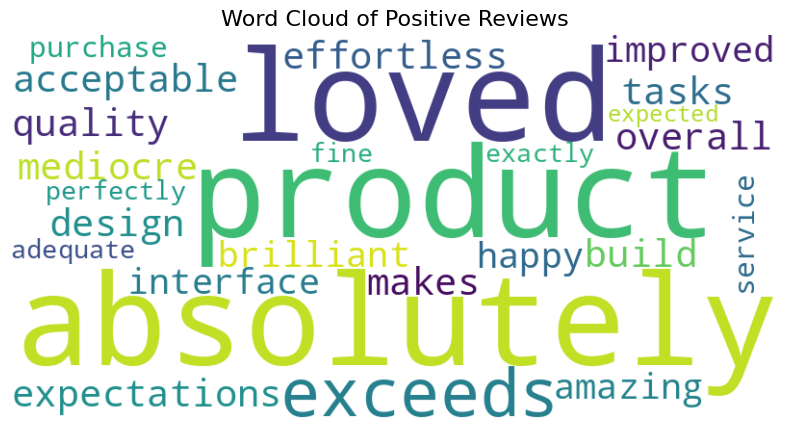

In [12]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud

reviews = [
    "I absolutely loved this product! It exceeds all my expectations and makes tasks effortless.",
    "The design is acceptable, but the overall build quality is mediocre and could be improved.",
    "Terrible customer service. The application constantly crashes and is highly frustrating to use.",
    "An amazing and brilliant interface! Very happy with my purchase.",
    "The service was perfectly fine and adequate, doing exactly what was expected."
]

sia = SentimentIntensityAnalyzer()
positive_texts = []

print("Review Classification:")
for r in reviews:
    scores = sia.polarity_scores(r)
    compound = scores['compound']

    if compound >= 0.05:
        sentiment = "Positive"
        positive_texts.append(r)
    elif compound <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"Review: \"{r}\"\n -> Polarity (Compound): {compound}, Classification: {sentiment}\n")

positive_corpus = " ".join(positive_texts)
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(positive_corpus)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Positive Reviews', fontsize=16)
plt.show()

Q6. Choose your own paragraph (~100 words) as training data.
1. Tokenize text using Tokenizer() from keras.preprocessing.text
2. Create input sequences and build a simple LSTM or Dense model
3. Train the model and generate 2–3 new lines of text star ng from any seed word you
provide.

In [13]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_paragraph = """
Deep learning algorithms are revolutionizing our modern world step by step.
These advanced neural structures learn complicated representations directly from raw structures.
Engineers use sequence models to anticipate complex future actions with high reliability.
Every single layer transforms input configurations into useful decision boundaries systematically.
This continuous optimization makes artificial neural processing systems incredibly robust over time.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_paragraph])
total_words = len(tokenizer.word_index) + 1

input_sequences = []
for line in training_paragraph.strip().split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

X_train, y_train = input_sequences[:,:-1], input_sequences[:,-1]
y_train = tf.keras.utils.to_categorical(y_train, num_classes=total_words)

model = Sequential([
    Embedding(total_words, 64, input_length=max_sequence_len-1),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=150, verbose=0)
print("Model trained successfully.\n")

def generate_text(seed_text, next_words_count):
    for _ in range(next_words_count):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len-1, padding='pre')
        predicted_probs = model.predict(token_list, verbose=0)
        predicted_idx = np.argmax(predicted_probs, axis=-1)[0]

        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted_idx:
                output_word = word
                break
        seed_text += " " + output_word
    return seed_text

print("Generated Text Line 1:", generate_text("deep learning", 5))
print("Generated Text Line 2:", generate_text("these advanced", 5))
print("Generated Text Line 3:", generate_text("every single", 5))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model trained successfully.

Generated Text Line 1: deep learning algorithms are revolutionizing our modern
Generated Text Line 2: these advanced neural structures learn complicated representations
Generated Text Line 3: every single layer transforms input configurations into
